# Setup

In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.size': 9,
    'axes.linewidth': 0.5,
    'lines.linewidth': 1.0,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
})

fontsize = 9
markers = ['o', 'x', '^', 'D', 'v', 'P']
markersize = 6
FIGURESIZE = (6.7, 6.7 * 3/7)
FILETYPE = '.pdf'

# H2 PES

## Helper Methods

In [3]:
from pathlib import Path
import json
from pyscf import gto, scf, fci

In [4]:
def remove_duplicates(lst, threshold=1e-5):
    unique = []
    for val in lst:
        if not any(abs(val - u) < threshold for u in unique):
            unique.append(val)
    return unique

def get_good_energies(folder_paths, min_overlap=1e-8, remove_duplicates_flag=True, duplicate_threshold=1e-6):
    all_energies = []
    all_overlaps = []
    
    for folder in folder_paths:
        with open(f"{folder}/energies.json") as f:
            all_energies.extend(json.load(f))
        with open(f"{folder}/overlaps.json") as f:
            overlaps_raw = json.load(f)
        all_overlaps.extend([[entry["overlap"] for entry in state] for state in overlaps_raw])
    
    good_indices = [i for i, state in enumerate(all_overlaps) if all(v < min_overlap for v in state)]
    good_energies = [all_energies[i] for i in good_indices]
    if remove_duplicates_flag:
        good_energies = remove_duplicates(good_energies, threshold=duplicate_threshold)
    good_energies.sort()
    return good_energies

def compute_fci_states_h2(R, nroots):
    mol = gto.M(atom=[['H', (i*R,0,0)] for i in range(2)],
                basis='sto-3g')
    mf = scf.RHF(mol).run(verbose=0)
    cis = fci.FCI(mol, mf.mo_coeff)
    e, _ = cis.kernel(nroots=nroots)
    return np.sort(e)

## Gather and Filter Energies

In [5]:
H2_Sliced_Dir = Path.cwd().parent / 'data' / 'H2_results'

In [6]:
h2_p25_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=0.25_V4", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-5)

h2_p5_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=0.5_V3", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-5)

h2_pt75_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=0.75_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_1_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=1_V2", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_1pt25_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=1.25_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_1pt5_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=1.5_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_1pt75_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=1.75_V2", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)

h2_2_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=2_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_2pt25_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=2.25_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_2pt54_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=2.54166667_V3", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)

h2_2pt83_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=2.833333333333_V4", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)

h2_3pt125_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=3.125_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_3pt42_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=3.4166666666_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_3pt71_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=3.708333333_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)
h2_4_vqd = get_good_energies([f"{H2_Sliced_Dir}/R=4_V1", ], min_overlap=1e-10, remove_duplicates_flag=True, duplicate_threshold=1e-6)

vqd_values_h2 = np.array([h2_p25_vqd, h2_p5_vqd, h2_pt75_vqd, h2_1_vqd, h2_1pt25_vqd, h2_1pt5_vqd, h2_1pt75_vqd, h2_2_vqd, h2_2pt25_vqd, h2_2pt54_vqd, h2_2pt83_vqd, h2_3pt125_vqd, h2_3pt42_vqd, h2_3pt71_vqd, h2_4_vqd])

In [7]:
max_level = max([len(en) for en in vqd_values_h2])

In [8]:
distances_h2 = np.concatenate((np.linspace(0.25, 2.0, 8),
                                     np.linspace(2.25, 4.0, 7)))
fci_values_h2 = np.array([compute_fci_states_h2(R, max_level) for R in distances_h2])

In [9]:
distances_dense_h2 = np.linspace(min(distances_h2), max(distances_h2), 500)
fci_values_dense_h2 = np.array([compute_fci_states_h2(R, 4)
                             for R in distances_dense_h2])

In [10]:
colors = [f'C{i}' for i in range(max_level)]

## Plot

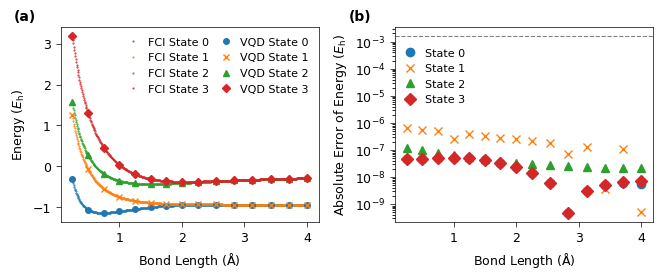

In [11]:


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): PES ---
for i in range(4):
    ax1.plot(distances_dense_h2, fci_values_dense_h2[:, i],
             label=f'FCI State {i}', linestyle='', markersize=0.5, marker='o', color=f'C{i}')
for i in range(4):
    ax1.plot(distances_h2, vqd_values_h2[:, i],
             label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=4, color=f'C{i}')

ax1.set_xlabel(r'Bond Length ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($E_\text{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1.0, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
for i in range(4):
    xs = [distances_h2[j] for j, en in enumerate(vqd_values_h2) if i < len(en)]
    ys = [abs(en[i] - fci_values_h2[j][i])
          for j, en in enumerate(vqd_values_h2) if i < len(en)]
    ax2.plot(xs, ys, marker=markers[i], linestyle='',
             markersize=markersize, color=colors[i], label=f'State {i}')


# error = np.abs(vqd_values - fci_values)
# colors = [f'C{i}' for i in range(4)]

# for i in range(fci_values.shape[1]):
#     ax2.plot(distances_plotting, error[:, i], marker=markers[i],
#              markersize=5, linestyle='', color=colors[i],
#              label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Bond Length ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\text{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0, loc='upper left', bbox_to_anchor=(0.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/H2_PES_and_Error{FILETYPE}', dpi=900, bbox_inches='tight')
plt.show()

# CO2/H2S

## Imports

In [12]:
from third_party.vibrational_dynamics.util_hamil import hamil

In [13]:
from openfermion.linalg import boson_operator_sparse

## Main code

In [14]:
name = 'CO2' # 'H2S' or 'CO2'
trunc = 4

In [15]:

if name == 'H2S':
    p = Path("..") / "data" / "H2S.hdf5"
elif name == 'CO2':
    p = Path("..") / "data" / "CO2.hdf5"

In [16]:
if p.exists():
    H = hamil(name)
    H_original_sparse = boson_operator_sparse(H, trunc=trunc)
    H_original_eigenenergies = np.linalg.eigvalsh(H_original_sparse.todense())
    expected = H_original_eigenenergies
    expected = [float(expect.real) for expect in expected]
else:
    print(f"Vibrational Hamiltonian file not found at  {p}.")

In [17]:
if name == 'H2S':
  H2S_VQD_Energies = [np.float64(3301.734323178507), np.float64(4563.385904767243),
                       np.float64(5807.2645136495), np.float64(5840.035908675143),
                         np.float64(5899.937131541012)] 
  H2S_VQD_Energies = [float(energy) for energy in H2S_VQD_Energies]
  en = H2S_VQD_Energies
elif name == 'CO2':
  en = [
  2535.2439214559486,
  3189.544660844184,
  3189.5446624782257,
  3829.124267040216,
  3847.1697717301276,
  3869.374810850096,
  ] # removed energies that were abnormally high or had high overlap values with previous energies. 

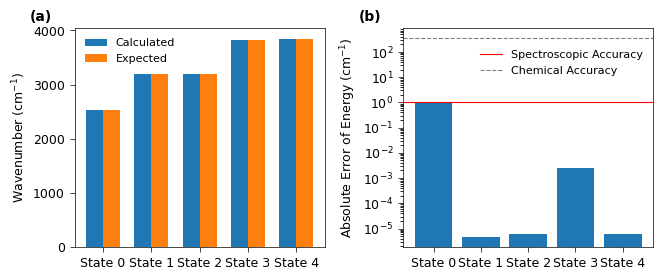

In [18]:
if name == 'H2S':
    max_idx = 5
elif name == 'CO2':
    max_idx = 5

en_subset = en[:max_idx]
expected_subset = expected[:max_idx]
errors = [abs(en_subset[i] - expected_subset[i]) for i in range(max_idx)]

labels = [f'State {i}' for i in range(max_idx)]
x = np.arange(max_idx)
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): Energies ---
ax1.bar(x - width/2, en_subset, width, label='Calculated')
ax1.bar(x + width/2, expected_subset, width, label='Expected')

ax1.set_ylabel(r'Wavenumber (cm$^{-1}$)', fontsize=fontsize)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=fontsize)
ax1.tick_params(axis='y', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, frameon=False)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')


# --- Panel (b): Errors ---
ax2.bar(x, errors)
ax2.set_yscale('log')
ax2.set_ylabel(r'Absolute Error of Energy (cm$^{-1}$)', fontsize=fontsize)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=fontsize)
ax2.tick_params(axis='y', labelsize=fontsize)

ax2.axhline(y=1, color='r', linestyle='-', linewidth=0.8,
            label='Spectroscopic Accuracy')
ax2.axhline(y=350, color='grey', linestyle='--', linewidth=0.8,
            label='Chemical Accuracy')
ax2.legend(fontsize=fontsize - 1, frameon=False, loc='upper right', bbox_to_anchor=(1.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/{name}_Energies_and_Errors{FILETYPE}', dpi=600, bbox_inches='tight')
plt.show()

## Harmonic Portion

In [19]:
from third_party.vibrational_dynamics.util_hamil import hamil
from third_party.vibrational_dynamics.bosonic_form import harmonic_oscillators
from openfermion.transforms import normal_ordered
from openfermion.linalg import boson_operator_sparse
import h5py

hartree_to_inverse_cm = 219474.63068
with h5py.File(Path("..") / "data" / f"{name}.hdf5", "r") as f:
    freqs = f["freqs"][()]

print("Harmonic frequencies (cm^-1):", freqs * hartree_to_inverse_cm)

H_harm = hartree_to_inverse_cm * normal_ordered(harmonic_oscillators(freqs))
H_harm_sparse = boson_operator_sparse(H_harm, trunc=trunc)
harmonic = np.linalg.eigvalsh(H_harm_sparse.todense())
harmonic = [float(e) for e in harmonic]

max_idx = 5
for i in range(max_idx):
    print(f"State {i}: harmonic {harmonic[i]:.1f}")

Harmonic frequencies (cm^-1): [ 656.31735828  656.31735828 1407.28481365 2373.63715923]
State 0: harmonic 2546.8
State 1: harmonic 3203.1
State 2: harmonic 3203.1
State 3: harmonic 3859.4
State 4: harmonic 3859.4


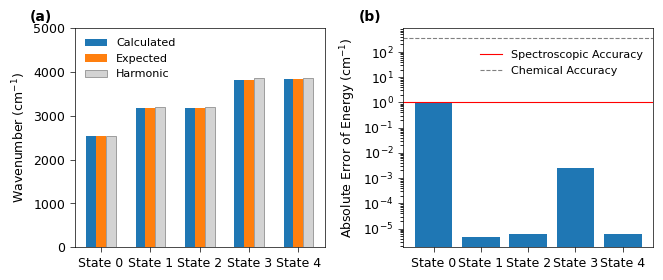

In [20]:
if name == 'H2S':
    max_idx = 5
elif name == 'CO2':
    max_idx = 5

en_subset = en[:max_idx]
expected_subset = expected[:max_idx]
harmonic_subset = harmonic[:max_idx]
errors = [abs(en_subset[i] - expected_subset[i]) for i in range(max_idx)]

labels = [f'State {i}' for i in range(max_idx)]
x = np.arange(max_idx)
width = 0.2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): Energies ---
# ax1.bar(x - width/2, en_subset, width, label='Calculated')
# ax1.bar(x + width/2, expected_subset, width, label='Expected')

ax1.bar(x - width, en_subset, width, label='Calculated')
ax1.bar(x,         expected_subset, width, label='Expected')
ax1.bar(x + width, harmonic_subset, width, label='Harmonic',
        color='lightgrey', edgecolor='grey', linewidth=0.5)

ax1.set_ylabel(r'Wavenumber (cm$^{-1}$)', fontsize=fontsize)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=fontsize)
ax1.tick_params(axis='y', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, frameon=False)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')
if name == 'CO2':
    ax1.set_ylim(0, 5000)

# --- Panel (b): Errors ---
ax2.bar(x, errors)
ax2.set_yscale('log')
ax2.set_ylabel(r'Absolute Error of Energy (cm$^{-1}$)', fontsize=fontsize)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=fontsize)
ax2.tick_params(axis='y', labelsize=fontsize)

ax2.axhline(y=1, color='r', linestyle='-', linewidth=0.8,
            label='Spectroscopic Accuracy')
ax2.axhline(y=350, color='grey', linestyle='--', linewidth=0.8,
            label='Chemical Accuracy')
ax2.legend(fontsize=fontsize - 1, frameon=False, loc='upper right', bbox_to_anchor=(1.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
# fig.savefig(f'Plots/{name}_Energies_and_Errors{FILETYPE}', dpi=600, bbox_inches='tight')
plt.show()

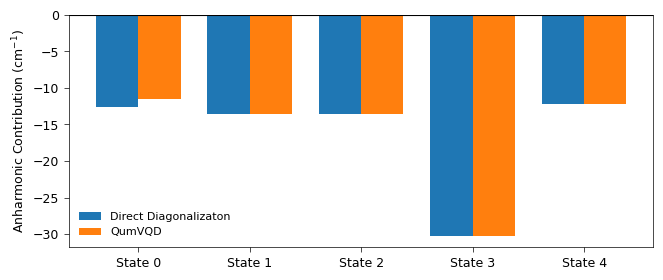

In [21]:
shift_exact = [expected[i] - harmonic[i] for i in range(max_idx)]
shift_qumvqd = [en_subset[i] - harmonic[i] for i in range(max_idx)]
labels = [f'State {i}' for i in range(max_idx)]
x = np.arange(max_idx)
width = 0.38

fig, ax = plt.subplots(figsize=(FIGURESIZE[0] , FIGURESIZE[1]))

ax.bar(x - width/2, shift_exact, width, label='Direct Diagonalizaton')
ax.bar(x + width/2, shift_qumvqd, width, label='QumVQD')
ax.axhline(0, color='k', linewidth=0.8)

ax.set_ylabel(r'Anharmonic Contribution (cm$^{-1}$)', fontsize=fontsize)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=fontsize)
ax.tick_params(axis='y', labelsize=fontsize)
ax.legend(fontsize=fontsize - 1, frameon=False)

fig.tight_layout()
fig.savefig(f'Plots/{name}_Anharmonic_Shift{FILETYPE}', dpi=600, bbox_inches='tight')
plt.show()

# Reduced H4

## VQD Energies

### Helper Methods

In [22]:
def compute_fci_states_h4(R, nroots):
    mol = gto.M(atom=[['H', (i*R,0,0)] for i in range(4)],
                basis='sto-3g')
    mf = scf.RHF(mol).run(verbose=0)
    cis = fci.FCI(mol, mf.mo_coeff)
    e, _ = cis.kernel(nroots=nroots)
    return np.sort(e)

### Gather and Filter Energies from Files

In [23]:
H4_Sliced_Dir = Path.cwd().parent / 'data' / 'Reduced_H4'

In [24]:
en_pt25_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=0.25", ], duplicate_threshold=1e-5)
print("Filtered energies for R=0.25:", en_pt25_vqd_filtered)

en_pt5_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=0.5"], min_overlap=1e-7)
print("Filtered energies for R=0.5:", en_pt5_vqd_filtered)

en_1_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=1.0", ], min_overlap=1e-7, duplicate_threshold=1e-3)
print("Filtered energies for R=1.0:", en_1_vqd_filtered)

en_1pt5_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=1.5",
                                           f"{H4_Sliced_Dir}/R=1.5_V2",
                                           f"{H4_Sliced_Dir}/R=1.5_V3",
                                           f"{H4_Sliced_Dir}/R=1.5_V4"
                                           ], min_overlap=1e-8, duplicate_threshold=1e-3)[:-1]
print("Filtered energies for R=1.5:", en_1pt5_vqd_filtered)

en_2_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=2.0",
                                        f"{H4_Sliced_Dir}/R=2.0_V2" ,], min_overlap=1e-7, duplicate_threshold=1e-3)
print("Filtered energies for R=2.0:", en_2_vqd_filtered)

vqd_values = [en_pt25_vqd_filtered, en_pt5_vqd_filtered, en_1_vqd_filtered, en_1pt5_vqd_filtered, en_2_vqd_filtered]
distances = [0.25, 0.5, 1.0, 1.5, 2.0]

Filtered energies for R=0.25: [1.5489096818807158, 3.2120538969622254, 3.4937532430518456, 4.362033117909343]
Filtered energies for R=0.5: [-1.6531169529366647, -0.9088625866824616, -0.6228269109803217, -0.336161118468299]
Filtered energies for R=1.0: [-2.1663874576950493, -1.9337570270040718, -1.7194809469135826]
Filtered energies for R=1.5: [-1.996150354718886, -1.9255585304523397, -1.8529031509076062, -1.8217488954102237, -1.7736606370282022]
Filtered energies for R=2.0: [-1.897717069160628, -1.8818777110225247, -1.8648625744657112, -1.856579970356115, -1.8476789439883634, -1.8400105858248224]


## FCI Energies

In [25]:
max_level = max([len(en) for en in vqd_values])

In [26]:
# Dense grid for smooth FCI reference curve

distances_dense = np.linspace(min(distances), max(distances), 500)
fci_values_dense = np.array([compute_fci_states_h4(R, max_level)
                             for R in distances_dense])

In [27]:
colors = [f'C{i}' for i in range(max_level)]

In [28]:
fci_values = np.array([compute_fci_states_h4(R, max_level) for R in distances])

## Plotting

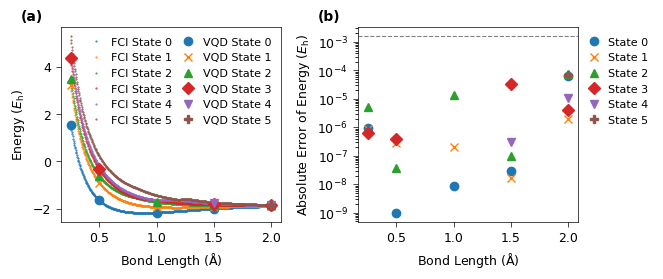

In [31]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): PES ---
for i in range(max_level):
    ax1.plot(distances_dense, fci_values_dense[:, i],
             label=f'FCI State {i}', linestyle='',markersize=0.5, marker='o', color=colors[i])


for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [en[i]        for en in vqd_values              if i < len(en)]
    ax1.plot(xs, ys, label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=markersize, color=colors[i])

ax1.set_xlabel(r'Bond Length ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [abs(en[i] - fci_values[j][i])
          for j, en in enumerate(vqd_values) if i < len(en)]
    ax2.plot(xs, ys, marker=markers[i], linestyle='',
             markersize=markersize, color=colors[i], label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Bond Length ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0,
           loc='upper left', bbox_to_anchor=(1, 1),)
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/Fig_H4_Sliced_PES_and_Error{FILETYPE}', dpi=600, bbox_inches='tight')
plt.show()